# Olist: data loading and orientation

This notebook loads the nine source files and establishes what is in them, before anything is changed. Cleaning decisions are made in `02_data_cleaning`; this one only asks what the data is.

## The business

Olist is a Brazilian marketplace that connects small sellers to large e-commerce channels. A customer buys through a channel such as Americanas or Mercado Livre, the order is routed to an independent seller, and the seller ships it through a carrier.

That arrangement creates the problem this project investigates. **The platform sets the delivery promise at checkout but controls neither of the parties who have to meet it.** The seller packs and dispatches; the carrier transports; Olist makes the promise. When the parcel is late the customer's complaint lands on the platform, in the form of a low review score and no second order.

Because the dataset records the promised date, the actual date, each handover between seller and carrier, the locations of both ends, the freight charged and the review that followed, the whole chain can be audited end to end.

## The dataset

[Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), published on Kaggle. Nine CSV files covering roughly 100,000 orders placed between September 2016 and October 2018, anonymised and released by Olist itself.

## This notebook

1. Load all nine files into a `raw` schema, unchanged.
2. Establish what one row means in each table, and what each is for.
3. Map how they join.
4. Look at the overall shape of the data: volume over time, order statuses, geography, reviews, delivery times.
5. State the questions the project will answer.

**Nothing is cleaned or corrected here.** Every file is read as text and stored as it arrived, so that any later figure can be traced back to the source. Numbers shown below are therefore first-look figures and some will change once duplicates and bad values are dealt with in `02_data_cleaning`.

In [55]:
import duckdb

con = duckdb.connect("../olist.duckdb")

def show(sql, n=20):
    con.sql(sql).show(max_rows=n)

print("duckdb", duckdb.__version__)

duckdb 2.0.0


## 1. Loading

Two decisions matter at load time.

**Everything is read as text** (`all_varchar=true`). Left to guess, DuckDB would read the zip code `01310` as the number 1310 and the leading zero would be gone before any analysis began. Reading as text preserves every file byte for byte; types are set deliberately during cleaning.

**Two files need special handling.** The review comments contain line breaks inside quoted fields, which the parallel CSV reader cannot parse, so that file is read single-threaded. The category translation file begins with a byte-order mark, an invisible character that attaches itself to the first column name and silently breaks every join that uses it - so its header is skipped and the columns are named explicitly.

In [56]:
con.sql("CREATE SCHEMA IF NOT EXISTS raw")

RAW = {
    "orders":         ("olist_orders_dataset.csv",          ""),
    "order_items":    ("olist_order_items_dataset.csv",     ""),
    "order_payments": ("olist_order_payments_dataset.csv",  ""),
    "order_reviews":  ("olist_order_reviews_dataset.csv",   ", parallel=false"),
    "customers":      ("olist_customers_dataset.csv",       ""),
    "sellers":        ("olist_sellers_dataset.csv",         ""),
    "products":       ("olist_products_dataset.csv",        ""),
    "geolocation":    ("olist_geolocation_dataset.csv",     ""),
}

for table, (fname, extra) in RAW.items():
    con.sql(f"""
        CREATE OR REPLACE TABLE raw.{table} AS
        SELECT * FROM read_csv('../data/{fname}', all_varchar=true{extra})
    """)

con.sql("""
    CREATE OR REPLACE TABLE raw.category_translation AS
    SELECT * FROM read_csv('../data/product_category_name_translation.csv',
                           header=false, skip=1, all_varchar=true,
                           names=['product_category_name', 'product_category_name_english'])
""")

print("loaded", len(RAW) + 1, "tables")

loaded 9 tables


In [57]:
expected = {
    "orders": 99441, "order_items": 112650, "order_payments": 103886,
    "order_reviews": 99224, "customers": 99441, "sellers": 3095,
    "products": 32951, "geolocation": 1000163, "category_translation": 71,
}

for t, n in expected.items():
    got = con.execute(f"SELECT COUNT(*) FROM raw.{t}").fetchall()[0][0]
    print(f"{t:22}{got:>9,}  expected {n:>9,}  {'OK' if got == n else 'MISMATCH'}")

orders                   99,441  expected    99,441  OK
order_items             112,650  expected   112,650  OK
order_payments          103,886  expected   103,886  OK
order_reviews            99,224  expected    99,224  OK
customers                99,441  expected    99,441  OK
sellers                   3,095  expected     3,095  OK
products                 32,951  expected    32,951  OK
geolocation           1,000,163  expected 1,000,163  OK
category_translation         71  expected        71  OK


## 2. What is in each table

The nine tables fall into four groups. Throughout, **grain** means what a single row represents - the thing that decides whether a later join inflates a number or not.

### 2a. The order itself

`orders` is the spine of the dataset. One row per order, carrying five timestamps that trace the order from purchase to doorstep, plus the date promised at checkout.

| Column | Event |
| --- | --- |
| `order_purchase_timestamp` | customer places the order |
| `order_approved_at` | payment clears |
| `order_delivered_carrier_date` | seller hands the parcel to the carrier |
| `order_delivered_customer_date` | parcel reaches the customer |
| `order_estimated_delivery_date` | the date promised at checkout |

Every delivery metric in the project is the difference between two of these. The gap between the last two is the entire subject of the analysis.

In [58]:
show("DESCRIBE raw.orders")
show("SELECT * FROM raw.orders LIMIT 3")

┌───────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│          column_name          │ column_type │  null   │   key   │ default │  extra  │
│            varchar            │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ order_id                      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_id                   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_status                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_purchase_timestamp      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_approved_at             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_delivered_carrier_date  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_delivered_customer_date │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_estimated_delivery_date 

### 2b. What was bought

Three tables describe the contents of an order.

`order_items` has one row per **item**, not per order - 112,650 rows against 99,441 orders. This distinction causes more errors than anything else in the dataset: joined to `orders` without aggregating first, every order-level value is duplicated once per item, and averages computed afterwards are silently weighted by basket size.

`products` describes each product: its category in Portuguese, its weight and its dimensions. Weight and size matter because freight is priced on them.

`category_translation` maps the Portuguese category names to English.

In [59]:
show("DESCRIBE raw.order_items")
show("SELECT * FROM raw.order_items LIMIT 3")

show("SELECT * FROM raw.products LIMIT 3")
show("SELECT * FROM raw.category_translation LIMIT 5")

# the grain difference, stated numerically
show("""
    SELECT
        COUNT(*)                        AS item_rows,
        COUNT(DISTINCT order_id)        AS orders,
        ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT order_id), 2) AS items_per_order,
        MAX(CAST(order_item_id AS INT)) AS most_items_in_one_order
    FROM raw.order_items
""")

┌─────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name     │ column_type │  null   │   key   │ default │  extra  │
│       varchar       │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ order_id            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_item_id       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ product_id          │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ seller_id           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ shipping_limit_date │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ price               │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ freight_value       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

┌──────────────────────────────────┬───────────────┬───────────

### 2c. Who and where

Three tables describe the two ends of every delivery.

`customers` has one row per **order-level customer record**, not per person. Olist regenerates `customer_id` for every order; `customer_unique_id` is the identifier meant to follow a person across orders. Any repeat-purchase question depends on the second one.

`sellers` has one row per seller, with a zip prefix, city and state.

`geolocation` maps zip prefixes to coordinates - but at one row per **coordinate point**, not per zip. A million rows cover nineteen thousand zips, so this table has to be collapsed before it can be joined to anything.

In [60]:
show("SELECT * FROM raw.customers LIMIT 3")
show("SELECT * FROM raw.sellers LIMIT 3")
show("SELECT * FROM raw.geolocation LIMIT 3")

show("""
    SELECT
        (SELECT COUNT(*) FROM raw.customers)                        AS customer_rows,
        (SELECT COUNT(DISTINCT customer_unique_id) FROM raw.customers) AS actual_people,
        (SELECT COUNT(*) FROM raw.sellers)                          AS sellers,
        (SELECT COUNT(*) FROM raw.geolocation)                      AS geo_rows,
        (SELECT COUNT(DISTINCT geolocation_zip_code_prefix) FROM raw.geolocation) AS geo_zips
""")

┌──────────────────────────────────┬──────────────────────────────────┬──────────────────────────┬───────────────────────┬────────────────┐
│           customer_id            │        customer_unique_id        │ customer_zip_code_prefix │     customer_city     │ customer_state │
│             varchar              │             varchar              │         varchar          │        varchar        │    varchar     │
├──────────────────────────────────┼──────────────────────────────────┼──────────────────────────┼───────────────────────┼────────────────┤
│ 06b8999e2fba1a1fbc88172c00ba8bc7 │ 861eff4711a542e4b93843c6dd7febb0 │ 14409                    │ franca                │ SP             │
│ 18955e83d337fd6b2def6b18a428ac77 │ 290c77bc529b7ac935b93aa66c333dc3 │ 09790                    │ sao bernardo do campo │ SP             │
│ 4e7b3e00288586ebd08712fdd0374a03 │ 060e732b5b29e8181a18229c7b0b2b5e │ 01151                    │ sao paulo             │ SP             │
└───────────────────

### 2d. What happened afterwards

`payments` has one row per **payment line**. A single order can be settled with several vouchers plus a card, so one order may have many rows.

`reviews` holds the survey Olist sent after each order, with a score from 1 to 5, an optional comment, and - importantly - the date the review was created. That date turns out to matter a great deal.

In [61]:
show("SELECT * FROM raw.order_payments LIMIT 3")
show("""
    SELECT review_id, order_id, review_score, review_creation_date, review_answer_timestamp
    FROM raw.order_reviews LIMIT 3
""")

show("""
    SELECT
        (SELECT COUNT(*) FROM raw.order_payments)                  AS payment_rows,
        (SELECT COUNT(DISTINCT order_id) FROM raw.order_payments)  AS orders_with_payment,
        (SELECT COUNT(*) FROM raw.order_reviews)                   AS review_rows,
        (SELECT COUNT(DISTINCT order_id) FROM raw.order_reviews)   AS orders_with_review
""")

┌──────────────────────────────────┬────────────────────┬──────────────┬──────────────────────┬───────────────┐
│             order_id             │ payment_sequential │ payment_type │ payment_installments │ payment_value │
│             varchar              │      varchar       │   varchar    │       varchar        │    varchar    │
├──────────────────────────────────┼────────────────────┼──────────────┼──────────────────────┼───────────────┤
│ b81ef226f3fe1789b1e8b2acac839d17 │ 1                  │ credit_card  │ 8                    │ 99.33         │
│ a9810da82917af2d9aefd1278f1dcfa0 │ 1                  │ credit_card  │ 1                    │ 24.39         │
│ 25e8ea4e93396b6fa0d3dd708e76c1bd │ 1                  │ credit_card  │ 1                    │ 65.71         │
└──────────────────────────────────┴────────────────────┴──────────────┴──────────────────────┴───────────────┘

┌──────────────────────────────────┬──────────────────────────────────┬──────────────┬─────────────────

## 3. How the tables join

Everything connects through `orders`.

```
                        customers ──┐
                                    │ customer_id
                                    ▼
    payments ──order_id──────►   ORDERS   ◄──order_id── reviews
                                    │
                                    │ order_id
                                    ▼
                               order_items
                                 │      │
                      product_id │      │ seller_id
                                 ▼      ▼
                           products    sellers
                                 │          │
                     category_name│          │ zip prefix
                                 ▼          ▼
                     category_translation  geolocation
```

| From | Column | To | Relationship |
| --- | --- | --- | --- |
| orders | customer_id | customers | one to one |
| order_items | order_id | orders | many to one |
| order_items | product_id | products | many to one |
| order_items | seller_id | sellers | many to one |
| payments | order_id | orders | many to one |
| reviews | order_id | orders | many to one |
| products | product_category_name | category_translation | many to one |
| customers, sellers | zip_code_prefix | geolocation | many to many |

Three of these are worth flagging now, because they shape every later decision.

**`orders` to `customers` is one to one**, not one to many, because `customer_id` is per order. The dataset's "customer" table is closer to a shipping address book than a customer list.

**`order_items` is the many side of three different relationships at once.** It is where an order, a product and a seller meet, which is why it has more rows than any other transactional table and why it must be aggregated before being joined back to order-level data.

**`geolocation` joins many to many.** Many coordinate points share a zip, and many customers share a zip. Joining it directly would multiply rows roughly fifty-fold; it has to be reduced to one row per zip first.

In [62]:
# every join tested for orphans: rows on the left with no match on the right
checks = [
    ("orders",      "customer_id",            "customers",            "customer_id"),
    ("order_items", "order_id",               "orders",               "order_id"),
    ("order_items", "product_id",             "products",             "product_id"),
    ("order_items", "seller_id",              "sellers",              "seller_id"),
    ("order_payments", "order_id",            "orders",               "order_id"),
    ("order_reviews",  "order_id",            "orders",               "order_id"),
    ("products",    "product_category_name",  "category_translation", "product_category_name"),
]

print("ORPHAN ROWS (left rows with no matching row on the right)")
for lt, lc, rt, rc in checks:
    n = con.execute(f"""
        SELECT COUNT(*) FROM raw.{lt} l
        LEFT JOIN raw.{rt} r ON r.{rc} = l.{lc}
        WHERE l.{lc} IS NOT NULL AND r.{rc} IS NULL""").fetchall()[0][0]
    print(f"  {lt+'.'+lc:38} -> {rt:22}{n:>8,}")

ORPHAN ROWS (left rows with no matching row on the right)
  orders.customer_id                     -> customers                    0
  order_items.order_id                   -> orders                       0
  order_items.product_id                 -> products                     0
  order_items.seller_id                  -> sellers                      0
  order_payments.order_id                -> orders                       0
  order_reviews.order_id                 -> orders                       0
  products.product_category_name         -> category_translation        13


Every join resolves except one: 13 products carry a category absent from the translation file. Those are two categories Olist omitted from its own lookup, and they are dealt with in cleaning. Nothing else is orphaned - every item resolves to a real order, product and seller, and every payment and review to a real order.

## 4. The shape of the data

Five questions to orient before any analysis: how much volume, over what period, in what condition, from where, and how satisfied were the customers.

In [63]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
BLUE = "#378ADD"
print("matplotlib ready")

matplotlib ready


### Volume over time

Orders by month of purchase. The series is built from a generated list of months rather than from the months present in the data, so that any month with no orders appears as a gap rather than vanishing from the axis.

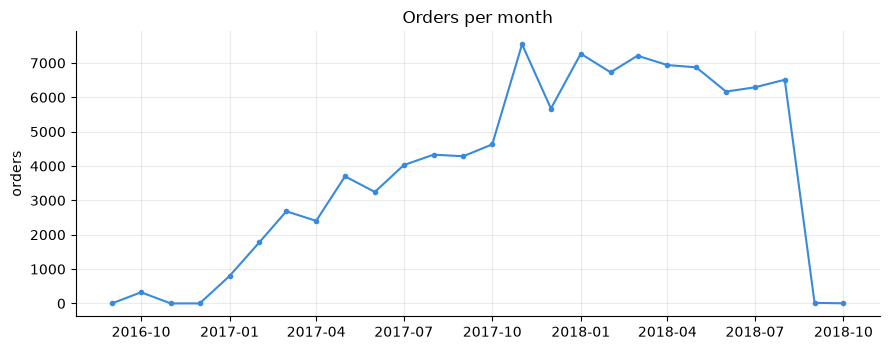

     month  orders
2016-09-01       4
2016-10-01     324
2016-11-01       0
2016-12-01       1
2018-09-01      16
2018-10-01       4


In [64]:
orders_by_month = con.execute("""
    WITH bounds AS (
        SELECT MIN(DATE_TRUNC('month', CAST(order_purchase_timestamp AS TIMESTAMP))) AS lo,
               MAX(DATE_TRUNC('month', CAST(order_purchase_timestamp AS TIMESTAMP))) AS hi
        FROM raw.orders
    ),
    months AS (
        SELECT CAST(m AS DATE) AS month
        FROM bounds, generate_series(bounds.lo, bounds.hi, INTERVAL 1 MONTH) t(m)
    ),
    counted AS (
        SELECT DATE_TRUNC('month', CAST(order_purchase_timestamp AS TIMESTAMP)) AS month,
               COUNT(*) AS orders
        FROM raw.orders GROUP BY 1
    )
    SELECT m.month, COALESCE(c.orders, 0) AS orders
    FROM months m LEFT JOIN counted c ON c.month = m.month
    ORDER BY 1
""").df()

fig, ax = plt.subplots()
ax.plot(orders_by_month["month"], orders_by_month["orders"], color=BLUE, marker="o", markersize=3)
ax.set_title("Orders per month")
ax.set_ylabel("orders")
plt.tight_layout(); plt.show()

print(orders_by_month[orders_by_month["orders"] < 500].to_string(index=False))

Three things stand out.

**The first four months are negligible** - 2016 contributes 329 orders in total, and November 2016 contains none at all. Any trend chart in this project should start in January 2017, and the 2016 tail should be excluded from year-on-year comparisons rather than presented as a baseline.

**Volume grows roughly tenfold across 2017** before flattening in 2018, which is a platform scaling rather than a seasonal pattern.

**November 2017 is a visible spike** - Black Friday. Whether the delivery operation absorbed it is one of the questions this project answers.

**The series stops abruptly.** September 2018 has 16 orders and October 2018 has 4, against roughly 6,500 a month earlier in the year. The dataset was cut mid-stream rather than ending naturally, so the final two months are incomplete and should be excluded from any trend or seasonality claim.

### Order status

Not every order was delivered. The status column decides which rows are eligible for delivery analysis at all.

order_status  orders   pct
   delivered   96478 97.02
     shipped    1107  1.11
    canceled     625  0.63
 unavailable     609  0.61
    invoiced     314  0.32
  processing     301  0.30
     created       5  0.01
    approved       2  0.00


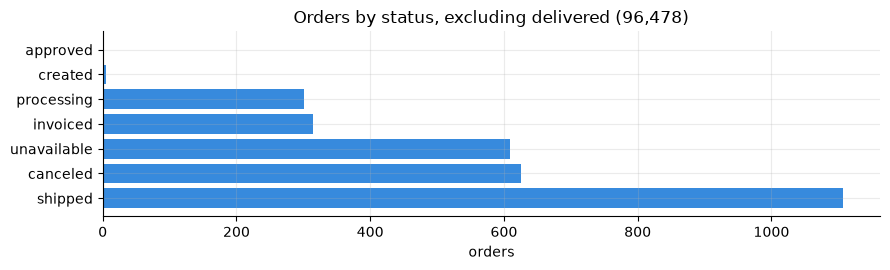

In [65]:
status = con.execute("""
    SELECT order_status, COUNT(*) AS orders,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM raw.orders GROUP BY 1 ORDER BY 2 DESC
""").df()
print(status.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 2.8))
rest = status[status["order_status"] != "delivered"]
ax.barh(rest["order_status"], rest["orders"], color=BLUE)
ax.set_title("Orders by status, excluding delivered (96,478)")
ax.set_xlabel("orders")
plt.tight_layout(); plt.show()

97% of orders were delivered, so the delivery analysis has nearly the full dataset to work with. The remaining 3% still matter: they include parcels that reached a carrier and never arrived, which a late rate computed on delivered orders cannot see, and orders that were paid for but never fulfilled, which explain most of the gap between payments and revenue.

### Geography

Where the orders go, and where the sellers are. These two distributions are not the same, and the difference is the source of the delivery problem.

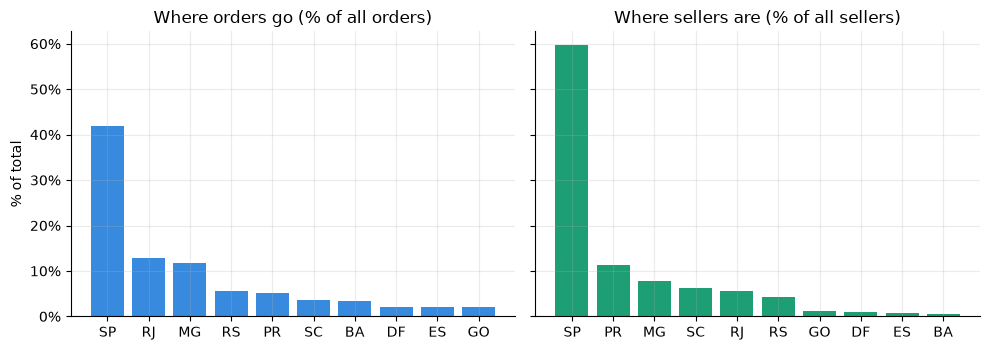

┌──────────────────┬───────────────────┐
│ pct_orders_to_SP │ pct_sellers_in_SP │
│      double      │      double       │
├──────────────────┼───────────────────┤
│             42.0 │              59.7 │
└──────────────────┴───────────────────┘



In [66]:
# shares, not counts: the two panels have different totals (99,441 orders vs 3,095 sellers),
# so raw bars cannot be compared across them
geo = con.execute("""
    SELECT c.customer_state AS state,
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct
    FROM raw.orders o JOIN raw.customers c USING (customer_id)
    GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""").df()

sellers_by_state = con.execute("""
    SELECT seller_state AS state,
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct
    FROM raw.sellers GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""").df()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
axes[0].bar(geo["state"], geo["pct"], color=BLUE)
axes[0].set_title("Where orders go (% of all orders)")
axes[0].set_ylabel("% of total")
axes[1].bar(sellers_by_state["state"], sellers_by_state["pct"], color="#1D9E75")
axes[1].set_title("Where sellers are (% of all sellers)")
for ax in axes:
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
plt.tight_layout(); plt.show()

show("""
    SELECT
        ROUND(100.0 * COUNT(*) FILTER (WHERE c.customer_state = 'SP') / COUNT(*), 1) AS pct_orders_to_SP,
        (SELECT ROUND(100.0 * COUNT(*) FILTER (WHERE seller_state = 'SP') / COUNT(*), 1)
         FROM raw.sellers)                                                           AS pct_sellers_in_SP
    FROM raw.orders o JOIN raw.customers c USING (customer_id)
""")

**Supply and demand are differently distributed.** 42% of orders go to São Paulo state, but 60% of sellers are based there. Demand is spread across Brazil while supply concentrates in the southeast, so a large share of parcels travel a long way - and the states furthest from the sellers are the ones with the least local supply to fall back on.

### Reviews

Scores from 1 to 5, collected by a survey Olist sent after each order.

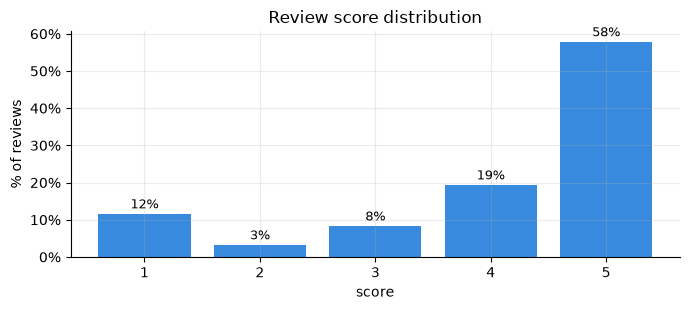

 score  reviews  pct
     1    11424 11.5
     2     3151  3.2
     3     8179  8.2
     4    19142 19.3
     5    57328 57.8


In [67]:
rev = con.execute("""
    SELECT CAST(review_score AS INT) AS score,
           COUNT(*)                                   AS reviews,
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER ()   AS pct
    FROM raw.order_reviews GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(rev["score"], rev["pct"], color=BLUE)
ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_title("Review score distribution")
ax.set_xlabel("score"); ax.set_ylabel("% of reviews")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
plt.tight_layout(); plt.show()

print(rev.round(1).to_string(index=False))

The distribution is strongly bimodal: 58% give five stars and 12% give one, with little in between. People review when delighted or angry, which means the scores behave more like a satisfied/dissatisfied flag than a scale, and should be analysed accordingly.

### Delivery times and the promise

The two numbers the whole project turns on: how long delivery actually took, and how that compared with what was promised.

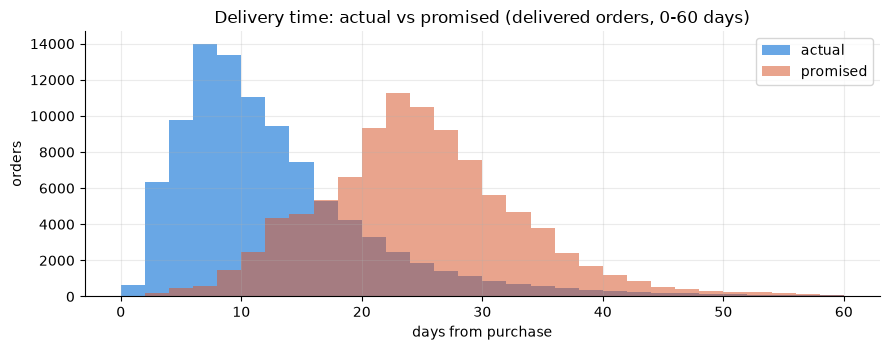

       delivery_days  promised_days
count        96470.0        96470.0
mean            12.5           24.4
std              9.6            8.8
min              0.0            3.0
25%              7.0           19.0
50%             10.0           24.0
75%             16.0           29.0
max            210.0          156.0


In [68]:
delivery = con.execute("""
    SELECT
        date_diff('day', CAST(order_purchase_timestamp AS TIMESTAMP),
                         CAST(order_delivered_customer_date AS TIMESTAMP)) AS delivery_days,
        date_diff('day', CAST(order_purchase_timestamp AS TIMESTAMP),
                         CAST(order_estimated_delivery_date AS TIMESTAMP)) AS promised_days
    FROM raw.orders
    WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
""").df()

fig, ax = plt.subplots()
bins = range(0, 61, 2)
ax.hist(delivery["delivery_days"], bins=bins, color=BLUE, alpha=0.75, label="actual")
ax.hist(delivery["promised_days"], bins=bins, color="#D85A30", alpha=0.55, label="promised")
ax.set_title("Delivery time: actual vs promised (delivered orders, 0-60 days)")
ax.set_xlabel("days from purchase"); ax.set_ylabel("orders")
ax.legend()
plt.tight_layout(); plt.show()

print(delivery.describe().round(1).to_string())

The two distributions barely overlap. The median order arrives in 10 days against a median promise of 24. **Olist is systematically promising about twice as long as delivery actually takes.**

The tails are worth noting too: the slowest delivery took 210 days, and the longest promise was 156 days.

That is the project's opening observation, and it reframes the question. The obvious reading of a low late rate is that the operation performs well. The alternative reading is that the promise is padded heavily enough to absorb almost any failure - which protects the on-time statistic while giving every customer a worse delivery date at checkout than they would otherwise get.

Which of those is true, and what the padding costs, is the first question the analysis takes up.

## 5. What this project asks

| Notebook | Question |
| --- | --- |
| 04 Delivery analysis | How often is the promise missed, and why? Are the sellers, the carriers or the promise itself the bottleneck, and what does lateness cost in reviews? |
| 05 Network analysis | Do customers in smaller states get worse service at the same distance, and do they pay more for it? |
| 06 Promise and early warning | What should count as slow, if not the promise, and can late orders be caught in time to act? |
| 07 Seller scorecard | Which sellers underperform on the part of the job they actually control? |

## Next

`02_data_cleaning` examines each of these nine tables for errors, duplicates and contradictions, and produces a cleaned version of each with every decision recorded.

In [69]:
con.close()
print("connection closed")

connection closed
